In [1]:
import os
import time
import random
import heapq
import glob
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, matthews_corrcoef, f1_score
from skimage.segmentation import mark_boundaries
from lime import lime_image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset

import torchvision
import torchvision.transforms as transforms
import torchvision.transforms.functional as TF
import torchvision.models as models

# ==============================================================================
# 🎛️ MASTER NOTEBOOK CONFIGURATION
# ==============================================================================
DATASET_NAME = "cifar10"       # Options: cifar10, fashionmnist, eurosat, isic
STRATEGY = "augmented"          # Options: baseline, augmented, tuned, augmented_tuned

EXPERIMENT_NAME = f"{DATASET_NAME}_{STRATEGY}"
SAVE_DIR = f"{EXPERIMENT_NAME}_models"
DATA_DIR = f"./data_{DATASET_NAME}"
DATASET_STATS = {
    "cifar10":      {"mean": (0.4914, 0.4822, 0.4465), "std": (0.2470, 0.2435, 0.2616), "in_channels": 3},
    "fashionmnist": {"mean": (0.2860,), "std": (0.3530,), "in_channels": 1}, # True grayscale stats
    "eurosat":      {"mean": (0.3444, 0.3803, 0.4078), "std": (0.2037, 0.1366, 0.1148), "in_channels": 3},
    "isic":         {"mean": (0.7630, 0.5456, 0.5700), "std": (0.1409, 0.1526, 0.1699), "in_channels": 3} 
}

DATASET_MEAN = DATASET_STATS[DATASET_NAME]["mean"]
DATASET_STD = DATASET_STATS[DATASET_NAME]["std"]
IN_CHANNELS = DATASET_STATS[DATASET_NAME]["in_channels"]

print(f"📊 Using Normalization Stats -> Mean: {DATASET_MEAN} | Std: {DATASET_STD}")

# Create the dedicated directories immediately
os.makedirs(SAVE_DIR, exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)

print("="*80)
print(f"🚀 INITIALIZED NOTEBOOK FOR: [{EXPERIMENT_NAME.upper()}]")
print(f"📁 Dataset Directory: {DATA_DIR}/")
print(f"📁 Artifacts Directory: ./{SAVE_DIR}/")
print("="*80)

# Hardware device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Global reproducibility setup
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)

📊 Using Normalization Stats -> Mean: (0.4914, 0.4822, 0.4465) | Std: (0.247, 0.2435, 0.2616)
🚀 INITIALIZED NOTEBOOK FOR: [CIFAR10_AUGMENTED]
📁 Dataset Directory: ./data_cifar10/
📁 Artifacts Directory: ./cifar10_augmented_models/
Using device: cuda


In [2]:
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import torch

# ==============================================================================
# 1. THE "KITCHEN SINK" TRAINING TRANSFORM (Augmented Regimen)
# ==============================================================================
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    
    # Safely converts 1-channel to 3-channel RGB (ignored if already RGB)
    transforms.Grayscale(num_output_channels=3), 
    
    # Standard Spatial Flips
    transforms.RandomHorizontalFlip(p=0.5),
    
    # State-of-the-Art Auto Augmentation
    transforms.RandAugment(num_ops=2, magnitude=9),
    
    # Pixel-level Color Jittering
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    
    # Tensor Conversion
    transforms.ToTensor(),
    
    # Structural Masking (Must be applied AFTER ToTensor)
    transforms.RandomErasing(p=0.3, scale=(0.02, 0.15), ratio=(0.3, 3.3), value=0),
    
    # Finally, normalize using dynamic dataset stats
    transforms.Normalize(DATASET_MEAN, DATASET_STD),
])

# ==============================================================================
# 2. THE STRICTLY CLEAN TEST TRANSFORM
# ==============================================================================
# WARNING: Never apply random augmentations to validation/test sets!
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(DATASET_MEAN, DATASET_STD),
])

# ==============================================================================
# 3. DATASET & DATALOADER INITIALIZATION
# ==============================================================================
# Load datasets using the dynamic DATA_DIR from Snippet 1
train_dataset = torchvision.datasets.CIFAR10(
    root=DATA_DIR,  
    train=True, 
    download=True, 
    transform=train_transform  # <--- Heavy Augmentation applied here
)

test_dataset = torchvision.datasets.CIFAR10(
    root=DATA_DIR,  
    train=False, 
    download=True, 
    transform=test_transform   # <--- Clean baseline applied here
)

batch_size = 32

train_loader = DataLoader(
    train_dataset, 
    batch_size=batch_size, 
    shuffle=True, 
    num_workers=2, 
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset, 
    batch_size=batch_size, 
    shuffle=False, 
    num_workers=2, 
    pin_memory=torch.cuda.is_available()
)

# Sanity check
sample_imgs, sample_labels = next(iter(train_loader))
print(f"Batch shape: {sample_imgs.shape}")  # Should output: torch.Size([32, 3, 224, 224])

Files already downloaded and verified
Files already downloaded and verified
Batch shape: torch.Size([32, 3, 224, 224])


In [3]:
import torchvision.models as models
import torch.nn as nn
import torch
from sklearn.model_selection import StratifiedKFold
from torch.utils.data import Subset
import time

# ==========================================
# Architectures
# ==========================================
class BaselineCNN(nn.Module):
    def __init__(self, num_classes=10, in_channels=3):
        super().__init__()
        self.features = nn.Sequential(
            # 🔥 DYNAMIC CHANNELS: Accepts 1 (Grayscale) or 3 (RGB)
            nn.Conv2d(in_channels, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2)
        )
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.gap(self.features(x)))

def build_model(name, num_classes=10, in_channels=3):
    if name == "Baseline_CNN":
        return BaselineCNN(num_classes=num_classes, in_channels=in_channels)
        
    elif name == "ResNet18":
        m = models.resnet18(weights=None)
        # 🔥 SURGICAL FIX: Replace first Conv layer if dataset is grayscale
        if in_channels != 3:
            m.conv1 = nn.Conv2d(in_channels, 64, kernel_size=7, stride=2, padding=3, bias=False)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
        return m
        
    elif name == "MobileNetV2":
        m = models.mobilenet_v2(weights=None)
        # 🔥 SURGICAL FIX: Replace first Conv layer if dataset is grayscale
        if in_channels != 3:
            m.features[0][0] = nn.Conv2d(in_channels, 32, kernel_size=3, stride=2, padding=1, bias=False)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)
        return m

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# ==========================================
# Step Logic
# ==========================================
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        _, preds = outputs.max(1)
        correct += preds.eq(labels).sum().item()
        total += labels.size(0)
    return running_loss / total, 100.0 * correct / total

@torch.no_grad()
def evaluate_epoch(model, loader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        running_loss += loss.item() * images.size(0)
        _, preds = outputs.max(1)
        correct += preds.eq(labels).sum().item()
        total += labels.size(0)
    return running_loss / total, 100.0 * correct / total

In [4]:
import os
import glob
import copy
import time
import torch
import numpy as np
from sklearn.model_selection import StratifiedKFold
from torch.utils.data import Subset, DataLoader
from tqdm.auto import tqdm

class EarlyStopping:
    def __init__(self, patience=5, min_delta=1e-4):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = float('inf')
        self.best_val_acc = 0.0
        self.best_train_acc = 0.0
        self.best_model_weights = None
        self.early_stop = False

    def step(self, val_loss, val_acc, train_acc, model):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.best_val_acc = val_acc
            self.best_train_acc = train_acc
            self.best_model_weights = copy.deepcopy(model.state_dict())
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True

    def restore_best_weights(self, model):
        if self.best_model_weights is not None:
            model.load_state_dict(self.best_model_weights)

K_FOLDS = 2 # Change to 5 for production
MAX_EPOCHS = 2 # Change to 50 for production
PATIENCE = 5
BATCH_SIZE = 32

# 🔥 DYNAMIC CLASS COUNT 
NUM_CLASSES = len(train_dataset.classes)
print(f"Dynamically detected {NUM_CLASSES} classes in the training dataset.")

targets = np.array(train_dataset.targets)
skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=42)
criterion = nn.CrossEntropyLoss()

models_to_benchmark = ["Baseline_CNN", "ResNet18", "MobileNetV2"]

for m_idx, model_name in enumerate(models_to_benchmark, 1):
    print("\n" + "="*80)
    print(f"🚀 ACTIVE BENCHMARK [{m_idx}/{len(models_to_benchmark)}]: {model_name}")
    print("="*80)
    
    for fold, (train_idx, val_idx) in enumerate(skf.split(np.zeros(len(targets)), targets), 1):
        
        search_pattern = f"{SAVE_DIR}/{model_name}_fold{fold}_val*_train*.pt"
        existing_files = glob.glob(search_pattern)
        
        if existing_files:
            print(f"\n>>> [SKIP] Found existing artifact for {model_name} Fold {fold}: {existing_files[0]}")
            continue
            
        print(f"\n>>> Model: [{model_name}] | Running Fold {fold}/{K_FOLDS}...")
        
        train_sub = Subset(train_dataset, train_idx)
        val_sub = Subset(train_dataset, val_idx)
        
        fold_train_loader = DataLoader(train_sub, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
        fold_val_loader = DataLoader(val_sub, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
        
        model = build_model(model_name, num_classes=NUM_CLASSES, in_channels=IN_CHANNELS).to(device)
        optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
        early_stopping = EarlyStopping(patience=PATIENCE)
        
        for epoch in range(1, MAX_EPOCHS + 1):
            model.train()
            running_loss, correct, total = 0.0, 0, 0
            
            pbar = tqdm(fold_train_loader, desc=f"[{model_name}] Fold {fold} | Ep {epoch:02d}", leave=False)
            for images, labels in pbar:
                images, labels = images.to(device), labels.to(device)
                optimizer.zero_grad()
                outputs = model(images)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()
                
                running_loss += loss.item() * images.size(0)
                _, preds = outputs.max(1)
                correct += preds.eq(labels).sum().item()
                total += labels.size(0)
                pbar.set_postfix({"loss": f"{running_loss / total:.4f}"})
                
            train_loss = running_loss / total
            train_acc = 100.0 * correct / total
            val_loss, val_acc = evaluate_epoch(model, fold_val_loader, criterion, device)
            
            print(f"[{model_name}] Fold {fold} Ep {epoch:02d} | Train Acc: {train_acc:.2f}% | Val Loss: {val_loss:.4f} (Acc: {val_acc:.2f}%)")
            
            early_stopping.step(val_loss, val_acc, train_acc, model)
            if early_stopping.early_stop:
                print(f" 🛑 Early stopping at epoch {epoch}.")
                break
                
        early_stopping.restore_best_weights(model)
        
        b_val = early_stopping.best_val_acc
        b_train = early_stopping.best_train_acc
        
        save_path = f"{SAVE_DIR}/{model_name}_fold{fold}_val{b_val:.2f}_train{b_train:.2f}.pt"
        
        torch.save({
            'model_name': model_name,
            'model_state_dict': model.state_dict(),
            'val_acc': b_val,
            'classes': getattr(train_dataset, 'classes', None), 
            'input_size': (3, 224, 224),
        }, save_path)
        print(f" -> ✅ Saved Artifact: {save_path}")

Dynamically detected 10 classes in the training dataset.

🚀 ACTIVE BENCHMARK [1/3]: Baseline_CNN

>>> Model: [Baseline_CNN] | Running Fold 1/2...


[Baseline_CNN] Fold 1 | Ep 01:   0%|          | 0/782 [00:00<?, ?it/s]

[Baseline_CNN] Fold 1 Ep 01 | Train Acc: 26.76% | Val Loss: 1.7743 (Acc: 35.80%)


[Baseline_CNN] Fold 1 | Ep 02:   0%|          | 0/782 [00:00<?, ?it/s]

[Baseline_CNN] Fold 1 Ep 02 | Train Acc: 36.70% | Val Loss: 1.6956 (Acc: 39.07%)
 -> ✅ Saved Artifact: cifar10_augmented_models/Baseline_CNN_fold1_val39.07_train36.70.pt

>>> Model: [Baseline_CNN] | Running Fold 2/2...


[Baseline_CNN] Fold 2 | Ep 01:   0%|          | 0/782 [00:00<?, ?it/s]

... (19 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7febfddc8820>
Traceback (most recent call last):
  File "/home/rishabhjp/anaconda3/envs/majorProject/lib/python3.10/site-packages/torch/utils/data/dataloader.py", line 1604, in __del__
    self._shutdown_workers()Exception ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x7febfddc8820>  File "/home/rishabhjp/anaconda3/envs/majorProject/lib/python3.10/site-packages/torch/utils/data/dataloader.py", line 1587, in _shutdown_workers

    Traceback (most recent call last):
if w.is_alive():  File "/home/rishabhjp/anaconda3/envs/majorProject/lib/python3.10/site-packages/torch/utils/data/dataloader.py", line 1604, in __del__

      File "/home/rishabhjp/anaconda3/envs/majorProject/lib/python3.10/multiprocessing/process.py", line 160, in is_alive
self._shutdown_workers()    
assert self._parent_pid == os.getpid(), 'can only test a child process'  File "/home/rishabhjp/anaconda3/envs/majorProject/lib/pyth

[MobileNetV2] Fold 2 Ep 01 | Train Acc: 30.92% | Val Loss: 1.8220 (Acc: 36.48%)


[MobileNetV2] Fold 2 | Ep 02:   0%|          | 0/782 [00:00<?, ?it/s]

[MobileNetV2] Fold 2 Ep 02 | Train Acc: 49.58% | Val Loss: 1.3299 (Acc: 53.10%)
 -> ✅ Saved Artifact: cifar10_augmented_models/MobileNetV2_fold2_val53.10_train49.58.pt


In [5]:
# ==============================================================================
# Module 3.1: The Perturbation Engine (Section 4.5.1 & 4.5.2)
# ==============================================================================
class PerturbationEngine:
    def __init__(self, mean, std):
        self.mean = mean
        self.std = std
        self.normalize = transforms.Normalize(mean=mean, std=std)

    def gaussian_blur(self, x: torch.Tensor, intensity: float) -> torch.Tensor:
        if intensity <= 0.0: return x
        sigma = float(0.1 + intensity * 4.9)
        k_size = int(3 + int(intensity * 6) * 2)
        return TF.gaussian_blur(x, kernel_size=[k_size, k_size], sigma=[sigma, sigma])

    def gaussian_noise(self, x: torch.Tensor, intensity: float) -> torch.Tensor:
        if intensity <= 0.0: return x
        noise_std = intensity * 0.35
        noise = torch.randn_like(x) * noise_std
        return torch.clamp(x + noise, 0.0, 1.0)

    def brightness_shift(self, x: torch.Tensor, intensity: float) -> torch.Tensor:
        if intensity <= 0.0: return x
        shift = intensity * 0.6
        return torch.clamp(x + shift, 0.0, 1.0)

    def rotation(self, x: torch.Tensor, intensity: float) -> torch.Tensor:
        if intensity <= 0.0: return x
        angle = intensity * 90.0
        return TF.rotate(x, angle=angle)

    def contrast_exposure(self, x: torch.Tensor, intensity: float) -> torch.Tensor:
        if intensity <= 0.0: return x
        factor = float(1.0 + intensity * 2.0)
        return TF.adjust_contrast(x, contrast_factor=factor)

    def apply_raw_perturbation(self, x: torch.Tensor, p_type: str, intensity: float) -> torch.Tensor:
        """Returns perturbed image in unnormalized [0, 1] range."""
        x = x.clone()
        if p_type == "gaussian_blur":
            out = self.gaussian_blur(x, intensity)
        elif p_type == "gaussian_noise":
            out = self.gaussian_noise(x, intensity)
        elif p_type == "brightness":
            out = self.brightness_shift(x, intensity)
        elif p_type == "rotation":
            out = self.rotation(x, intensity)
        elif p_type == "contrast":
            out = self.contrast_exposure(x, intensity)
        elif p_type == "sensor_interference":  # Blur + Noise
            out = self.gaussian_blur(x, intensity * 0.8)
            out = self.gaussian_noise(out, intensity * 0.8)
        elif p_type == "environmental_obstruction":  # Blur + Brightness
            out = self.gaussian_blur(x, intensity * 0.7)
            out = self.brightness_shift(out, intensity * 0.7)
        elif p_type == "capture_instability":  # Rotation + Blur
            out = self.rotation(x, intensity * 0.8)
            out = self.gaussian_blur(out, intensity * 0.8)
        else:
            raise ValueError(f"Unknown perturbation: {p_type}")
        return out

    def apply_perturbation(self, x: torch.Tensor, p_type: str, intensity: float) -> torch.Tensor:
        """Returns perturbed image normalized for PyTorch model ingestion."""
        raw_perturbed = self.apply_raw_perturbation(x, p_type, intensity)
        return self.normalize(raw_perturbed)

# ==============================================================================
# Module 3.2: Adaptive Heuristic Sampling (Fragility Gradient)
# ==============================================================================
class AdaptiveSamplingEngine:
    def __init__(self, model, dataloader, engine: PerturbationEngine, device):
        self.model = model.to(device)
        self.model.eval()
        self.dataloader = dataloader
        self.engine = engine
        self.device = device

    @torch.no_grad()
    def evaluate_at_intensity(self, p_type: str, intensity: float, max_batches: int = None) -> float:
        correct, total = 0, 0
        for b_idx, (images, labels) in enumerate(self.dataloader):
            if max_batches and b_idx >= max_batches:
                break
            perturbed_images = self.engine.apply_perturbation(images, p_type, intensity).to(self.device)
            labels = labels.to(self.device)
            outputs = self.model(perturbed_images)
            _, preds = outputs.max(1)
            correct += preds.eq(labels).sum().item()
            total += labels.size(0)
        return (correct / total) * 100.0

    def run_adaptive_sampling(self, p_type: str, max_evals: int = 9, max_batches: int = 15):
        eval_cache = {}
        acc_min = self.evaluate_at_intensity(p_type, 0.0, max_batches=max_batches)
        acc_max = self.evaluate_at_intensity(p_type, 1.0, max_batches=max_batches)
        eval_cache[0.0] = acc_min
        eval_cache[1.0] = acc_max

        heap = []
        def compute_slope(x1, x2):
            dx = x2 - x1
            dy = eval_cache[x2] - eval_cache[x1]
            return abs(dy / dx) if dx > 0 else 0.0

        heapq.heappush(heap, (-compute_slope(0.0, 1.0), 0.0, 1.0))

        while len(eval_cache) < max_evals and heap:
            neg_slope, x1, x2 = heapq.heappop(heap)
            x_mid = round((x1 + x2) / 2.0, 4)
            if x_mid in eval_cache or abs(x2 - x1) < 1e-3:
                continue

            acc_mid = self.evaluate_at_intensity(p_type, x_mid, max_batches=max_batches)
            eval_cache[x_mid] = acc_mid

            heapq.heappush(heap, (-compute_slope(x1, x_mid), x1, x_mid))
            heapq.heappush(heap, (-compute_slope(x_mid, x2), x_mid, x2))

        sorted_samples = sorted(eval_cache.items(), key=lambda x: x[0])
        intensities, accuracies = zip(*sorted_samples)
        
        # Determine Critical Failure Threshold (Intensity where steepest accuracy collapse occurred)
        steepest_grad = -1.0
        critical_threshold = 0.5
        for idx in range(len(intensities) - 1):
            dx = intensities[idx+1] - intensities[idx]
            dy = abs(accuracies[idx+1] - accuracies[idx])
            grad = dy / dx if dx > 0 else 0.0
            if grad > steepest_grad:
                steepest_grad = grad
                critical_threshold = (intensities[idx] + intensities[idx+1]) / 2.0

        return list(intensities), list(accuracies), critical_threshold

In [6]:
class MetricEngine:
    """
    Module 4: Computes Accuracy, MCC, F1, Flip Rate, ECE, and NLL.
    """
    @staticmethod
    def calculate_ece(probs: np.ndarray, labels: np.ndarray, n_bins: int = 15) -> float:
        """Calculates Expected Calibration Error (ECE)."""
        bin_boundaries = np.linspace(0, 1, n_bins + 1)
        confidences = np.max(probs, axis=1)
        predictions = np.argmax(probs, axis=1)
        accuracies = (predictions == labels)

        ece = 0.0
        for i in range(n_bins):
            bin_lower, bin_upper = bin_boundaries[i], bin_boundaries[i+1]
            in_bin = (confidences > bin_lower) & (confidences <= bin_upper)
            prop_in_bin = np.mean(in_bin)

            if prop_in_bin > 0:
                accuracy_in_bin = np.mean(accuracies[in_bin])
                avg_confidence_in_bin = np.mean(confidences[in_bin])
                ece += np.abs(avg_confidence_in_bin - accuracy_in_bin) * prop_in_bin
        return float(ece)

    @torch.no_grad()
    def evaluate_comprehensive_metrics(self, model, dataloader, engine: PerturbationEngine, 
                                       p_type: str, intensity: float, device, max_batches: int = 20):
        model.eval()
        
        all_clean_preds = []
        all_pert_preds = []
        all_labels = []
        all_pert_probs = []
        nll_losses = []

        nll_criterion = nn.CrossEntropyLoss()

        for b_idx, (images, labels) in enumerate(dataloader):
            if max_batches and b_idx >= max_batches:
                break
                
            labels_dev = labels.to(device)
            
            # Clean baseline inference
            clean_images = engine.normalize(images.clone()).to(device)
            clean_logits = model(clean_images)
            _, clean_preds = clean_logits.max(1)
            
            # Perturbed inference
            pert_images = engine.apply_perturbation(images, p_type, intensity).to(device)
            pert_logits = model(pert_images)
            pert_loss = nll_criterion(pert_logits, labels_dev)
            
            pert_probs = F.softmax(pert_logits, dim=1)
            _, pert_preds = pert_logits.max(1)

            # Store for batch-independent calculation
            all_clean_preds.extend(clean_preds.cpu().numpy())
            all_pert_preds.extend(pert_preds.cpu().numpy())
            all_labels.extend(labels.numpy())
            all_pert_probs.extend(pert_probs.cpu().numpy())
            nll_losses.append(pert_loss.item())

        y_true = np.array(all_labels)
        y_pred = np.array(all_pert_preds)
        y_clean = np.array(all_clean_preds)
        probs = np.array(all_pert_probs)

        # 1. Classification Metrics
        acc = accuracy_score(y_true, y_pred) * 100.0
        mcc = matthews_corrcoef(y_true, y_pred)
        macro_f1 = f1_score(y_true, y_pred, average='macro')

        # 2. Instability Metric: Flip Rate (Fraction of clean predictions that altered under noise)
        flip_rate = np.mean(y_clean != y_pred) * 100.0

        # 3. Calibration Metrics
        ece = self.calculate_ece(probs, y_true, n_bins=15)
        nll = float(np.mean(nll_losses))

        return {
            "Accuracy (%)": acc,
            "MCC": mcc,
            "Macro F1": macro_f1,
            "Flip Rate (%)": flip_rate,
            "ECE": ece,
            "NLL": nll
        }

In [7]:
class LIMEExplainabilityEngine:
    """
    Module 5: Generates LIME superpixel explanations at critical failure thresholds.
    """
    def __init__(self, model, engine: PerturbationEngine, classes, device):
        self.model = model.to(device)
        self.model.eval()
        self.engine = engine
        self.classes = classes
        self.device = device
        self.explainer = lime_image.LimeImageExplainer()

    def _batch_predict(self, numpy_images: np.ndarray) -> np.ndarray:
        """Wrapper function for LIME: takes numpy images (N, H, W, 3) in [0, 1] and returns class probabilities."""
        self.model.eval()
        # Convert (N, H, W, C) -> (N, C, H, W)
        tensor_batch = torch.tensor(numpy_images, dtype=torch.float32).permute(0, 3, 1, 2)
        norm_batch = self.engine.normalize(tensor_batch).to(self.device)
        with torch.no_grad():
            logits = self.model(norm_batch)
            probs = F.softmax(logits, dim=1).cpu().numpy()
        return probs

    def explain_critical_sample(self, raw_img_tensor: torch.Tensor, label_idx: int, 
                                p_type: str, critical_intensity: float, num_samples: int = 150):
        """
        Generates side-by-side LIME visualizations: Clean focus vs Perturbed focus at threshold.
        """
        # Ensure single image shape (3, H, W)
        if raw_img_tensor.dim() == 4:
            raw_img_tensor = raw_img_tensor.squeeze(0)

        # 1. Prepare Clean Image (H, W, 3) numpy in [0, 1]
        clean_np = raw_img_tensor.permute(1, 2, 0).cpu().numpy()
        
        # 2. Prepare Perturbed Image at Critical Threshold
        pert_tensor = self.engine.apply_raw_perturbation(raw_img_tensor.unsqueeze(0), p_type, critical_intensity).squeeze(0)
        pert_np = pert_tensor.permute(1, 2, 0).cpu().numpy()

        # Generate LIME explanations
        clean_explanation = self.explainer.explain_instance(
            clean_np.astype(np.double), 
            self._batch_predict, 
            top_labels=1, 
            hide_color=0, 
            num_samples=num_samples
        )
        
        pert_explanation = self.explainer.explain_instance(
            pert_np.astype(np.double), 
            self._batch_predict, 
            top_labels=1, 
            hide_color=0, 
            num_samples=num_samples
        )

        clean_top_pred = clean_explanation.top_labels[0]
        pert_top_pred = pert_explanation.top_labels[0]

        temp_clean, mask_clean = clean_explanation.get_image_and_mask(
            clean_top_pred, positive_only=True, num_features=5, hide_rest=False
        )
        temp_pert, mask_pert = pert_explanation.get_image_and_mask(
            pert_top_pred, positive_only=True, num_features=5, hide_rest=False
        )

        # Plot Comparative Focus Shift
        fig, axes = plt.subplots(1, 4, figsize=(16, 4))
        
        axes[0].imshow(clean_np)
        axes[0].set_title(f"Clean Input\nTrue: {self.classes[label_idx]}", fontsize=10)
        axes[0].axis('off')

        axes[1].imshow(mark_boundaries(temp_clean, mask_clean))
        axes[1].set_title(f"Clean LIME Focus\nPred: {self.classes[clean_top_pred]}", fontsize=10)
        axes[1].axis('off')

        axes[2].imshow(pert_np)
        axes[2].set_title(f"Perturbed (I={critical_intensity:.2f})\nType: {p_type}", fontsize=10)
        axes[2].axis('off')

        axes[3].imshow(mark_boundaries(temp_pert, mask_pert))
        axes[3].set_title(f"Perturbed LIME Focus\nPred: {self.classes[pert_top_pred]}", fontsize=10)
        axes[3].axis('off')

        plt.suptitle(f"Spatial Attention Shift Analysis at Critical Threshold", fontsize=12, fontweight='bold')
        plt.tight_layout()
        plt.show()

Files already downloaded and verified
Loaded Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

📥 SCANNING FOR BEST CHECKPOINTS IN: cifar10_augmented_models/
[Baseline_CNN] Loading top performer: Baseline_CNN_fold1_val39.07_train36.70.pt
[ResNet18] Loading top performer: ResNet18_fold1_val54.33_train53.32.pt
[MobileNetV2] Loading top performer: MobileNetV2_fold1_val54.72_train48.98.pt


/tmp/ipykernel_27925/60459954.py:59: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(best_file, map_location=device)



🚀 INITIATING MODULE 3 -> 4 -> 5 PIPELINE ACROSS ALL PERTURBATIONS


Master Evaluation Suite:   0%|          | 0/8 [00:00<?, ?it/s]



★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★
  EVALUATING PERTURBATION: [GAUSSIAN_BLUR]
★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★


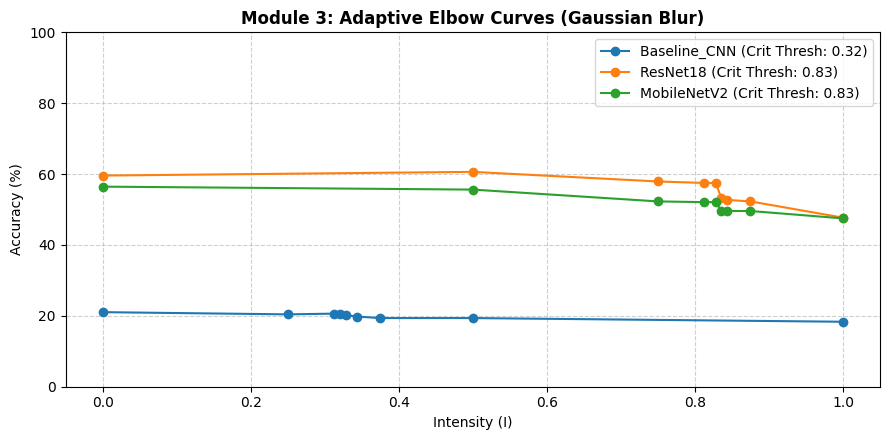


📊 MODULE 4: STATISTICAL METRICS AT CRITICAL THRESHOLDS (GAUSSIAN_BLUR)
-----------------------------------------------------------------------------------------------
Model          | Thresh   | Accuracy   | MCC      | Macro F1   | Flip Rate   | ECE      | NLL     
-----------------------------------------------------------------------------------------------
Baseline_CNN   | 0.32     | 21.41      | 0.137    | 0.160      | 5.31        | 0.2380   | 2.5678  
ResNet18       | 0.83     | 57.66      | 0.535    | 0.576      | 19.38       | 0.0529   | 1.1956  
MobileNetV2    | 0.83     | 53.59      | 0.495    | 0.509      | 20.00       | 0.0564   | 1.2613  
-----------------------------------------------------------------------------------------------

🔍 MODULE 5: LIME QUALITATIVE FOCUS SHIFT (GAUSSIAN_BLUR)
>>> Explaining [Baseline_CNN] failure at I=0.32 (Flipped to: dog)


  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

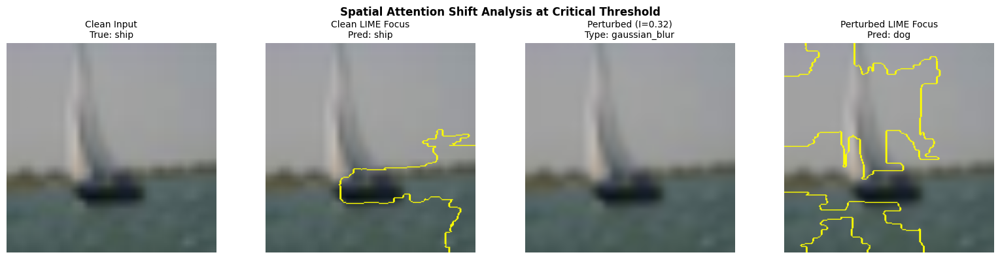

>>> Explaining [ResNet18] failure at I=0.83 (Flipped to: dog)


  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

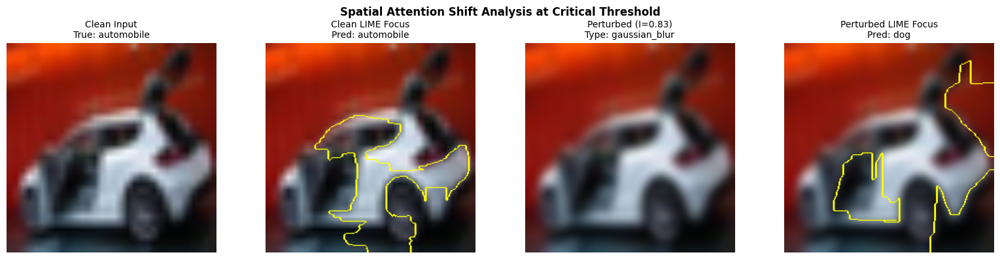

>>> Explaining [MobileNetV2] failure at I=0.83 (Flipped to: bird)


  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

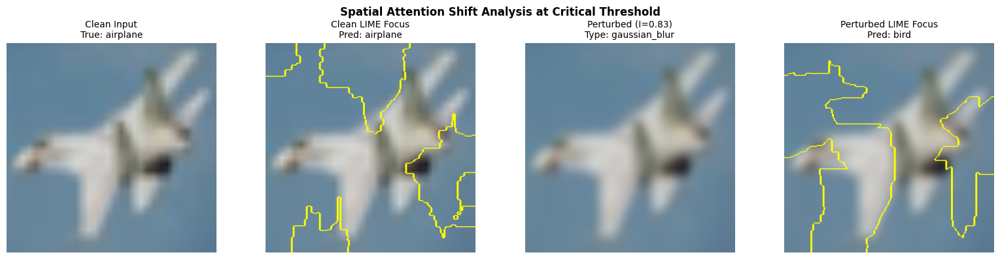



★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★
  EVALUATING PERTURBATION: [GAUSSIAN_NOISE]
★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★


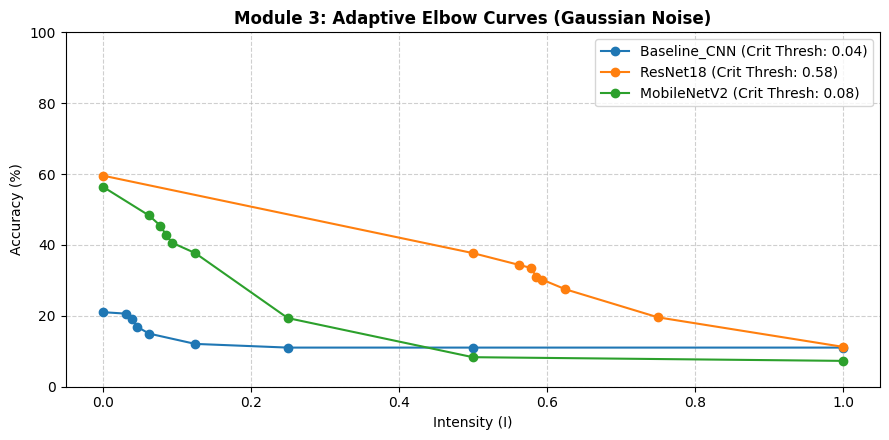


📊 MODULE 4: STATISTICAL METRICS AT CRITICAL THRESHOLDS (GAUSSIAN_NOISE)
-----------------------------------------------------------------------------------------------
Model          | Thresh   | Accuracy   | MCC      | Macro F1   | Flip Rate   | ECE      | NLL     
-----------------------------------------------------------------------------------------------
Baseline_CNN   | 0.04     | 17.34      | 0.102    | 0.134      | 26.56       | 0.3251   | 2.7017  
ResNet18       | 0.58     | 32.19      | 0.296    | 0.326      | 55.78       | 0.2435   | 2.0030  
MobileNetV2    | 0.08     | 48.28      | 0.440    | 0.462      | 35.00       | 0.1044   | 1.5077  
-----------------------------------------------------------------------------------------------

🔍 MODULE 5: LIME QUALITATIVE FOCUS SHIFT (GAUSSIAN_NOISE)
>>> Explaining [Baseline_CNN] failure at I=0.04 (Flipped to: airplane)


  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

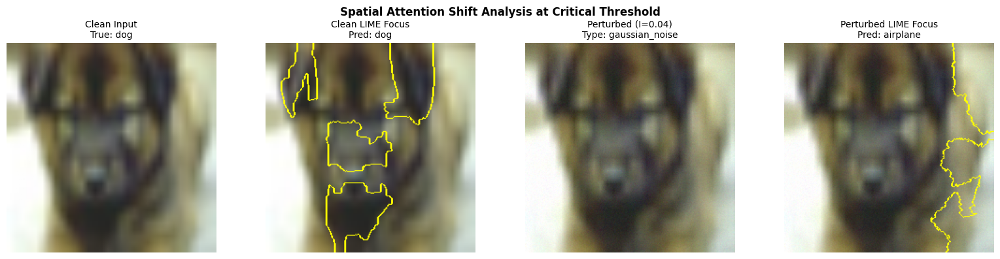

>>> Explaining [ResNet18] failure at I=0.58 (Flipped to: deer)


  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

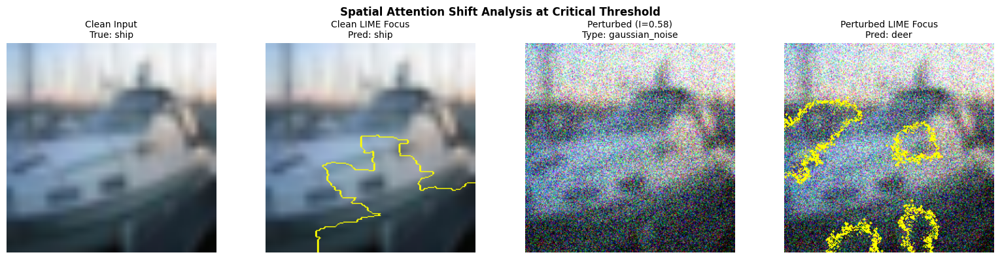

>>> Explaining [MobileNetV2] failure at I=0.08 (Flipped to: ship)


  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

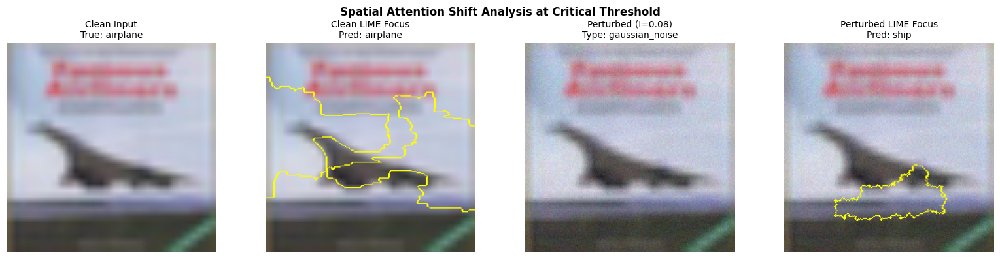



★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★
  EVALUATING PERTURBATION: [BRIGHTNESS]
★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★


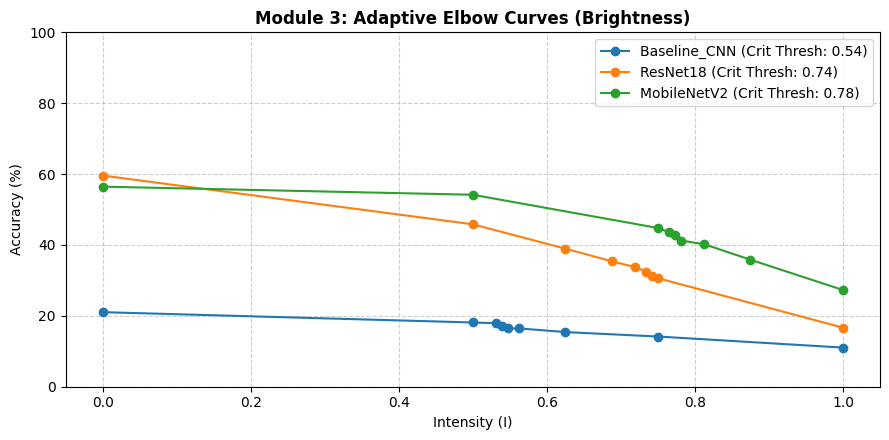


📊 MODULE 4: STATISTICAL METRICS AT CRITICAL THRESHOLDS (BRIGHTNESS)
-----------------------------------------------------------------------------------------------
Model          | Thresh   | Accuracy   | MCC      | Macro F1   | Flip Rate   | ECE      | NLL     
-----------------------------------------------------------------------------------------------
Baseline_CNN   | 0.54     | 16.25      | 0.085    | 0.113      | 39.69       | 0.2577   | 2.7298  
ResNet18       | 0.74     | 33.91      | 0.281    | 0.320      | 60.31       | 0.1405   | 1.9963  
MobileNetV2    | 0.78     | 41.72      | 0.359    | 0.407      | 54.06       | 0.0556   | 1.5903  
-----------------------------------------------------------------------------------------------

🔍 MODULE 5: LIME QUALITATIVE FOCUS SHIFT (BRIGHTNESS)
>>> Explaining [Baseline_CNN] failure at I=0.54 (Flipped to: airplane)


  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

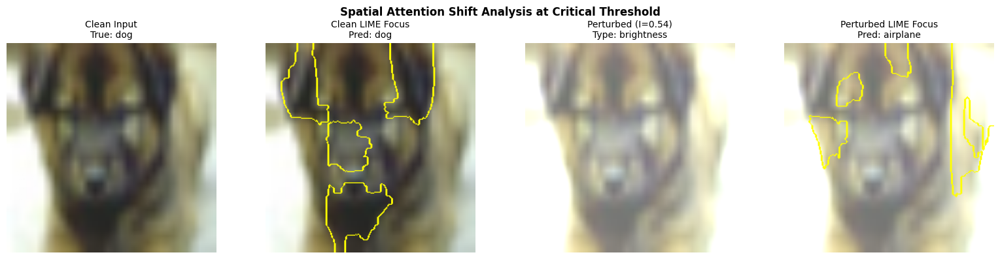

>>> Explaining [ResNet18] failure at I=0.74 (Flipped to: airplane)


  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

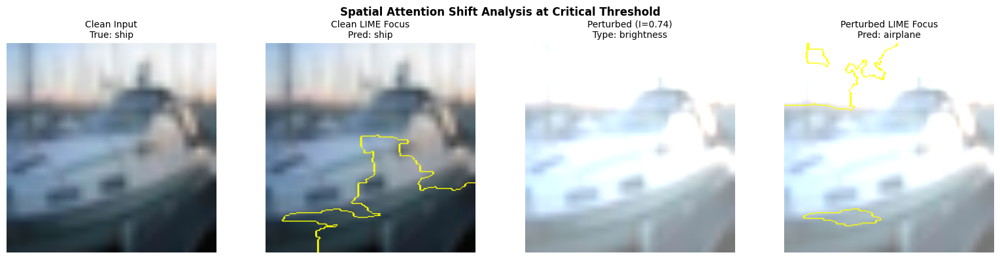

>>> Explaining [MobileNetV2] failure at I=0.78 (Flipped to: ship)


  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

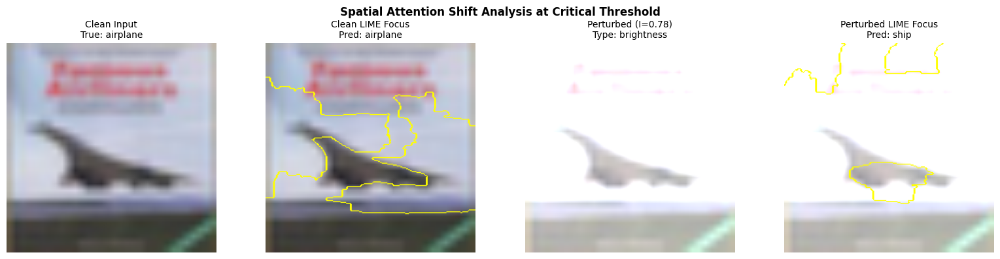



★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★
  EVALUATING PERTURBATION: [ROTATION]
★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★


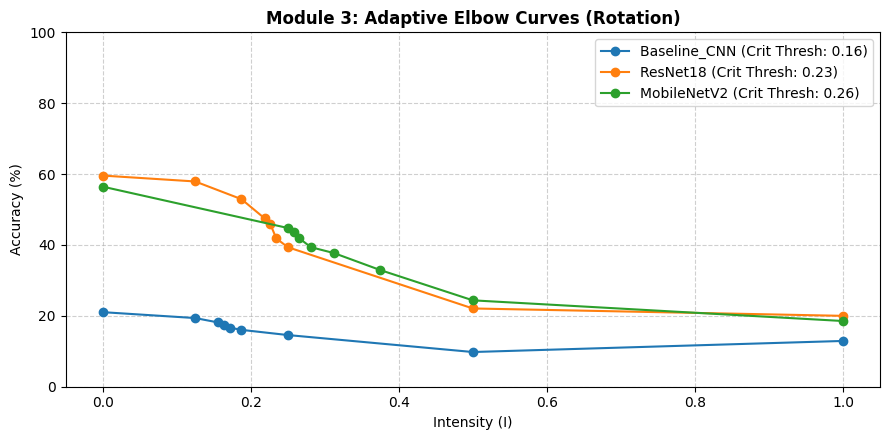


📊 MODULE 4: STATISTICAL METRICS AT CRITICAL THRESHOLDS (ROTATION)
-----------------------------------------------------------------------------------------------
Model          | Thresh   | Accuracy   | MCC      | Macro F1   | Flip Rate   | ECE      | NLL     
-----------------------------------------------------------------------------------------------
Baseline_CNN   | 0.16     | 17.50      | 0.098    | 0.137      | 20.16       | 0.2531   | 2.5737  
ResNet18       | 0.23     | 43.28      | 0.379    | 0.424      | 43.75       | 0.0882   | 1.5451  
MobileNetV2    | 0.26     | 43.44      | 0.381    | 0.400      | 42.81       | 0.0952   | 1.6020  
-----------------------------------------------------------------------------------------------

🔍 MODULE 5: LIME QUALITATIVE FOCUS SHIFT (ROTATION)
>>> Explaining [Baseline_CNN] failure at I=0.16 (Flipped to: airplane)


  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

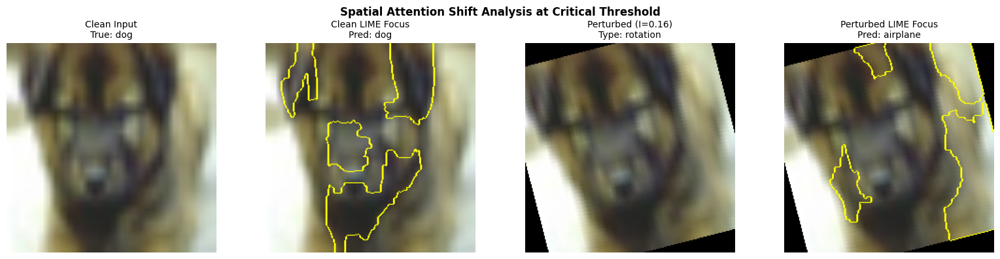

>>> Explaining [ResNet18] failure at I=0.23 (Flipped to: frog)


  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

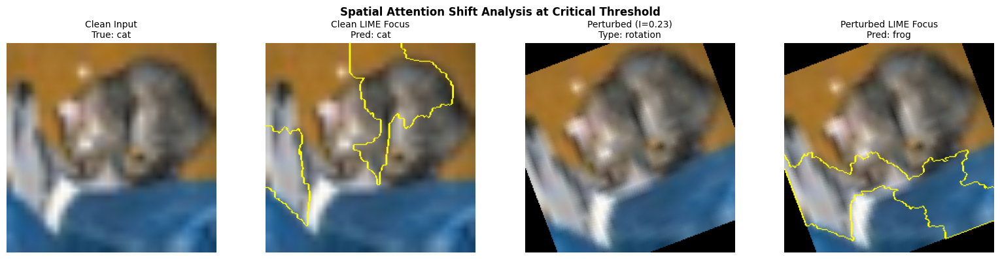

>>> Explaining [MobileNetV2] failure at I=0.26 (Flipped to: frog)


  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

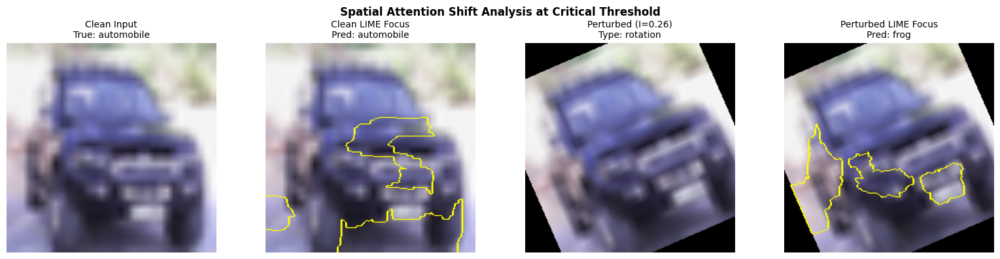



★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★
  EVALUATING PERTURBATION: [CONTRAST]
★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★


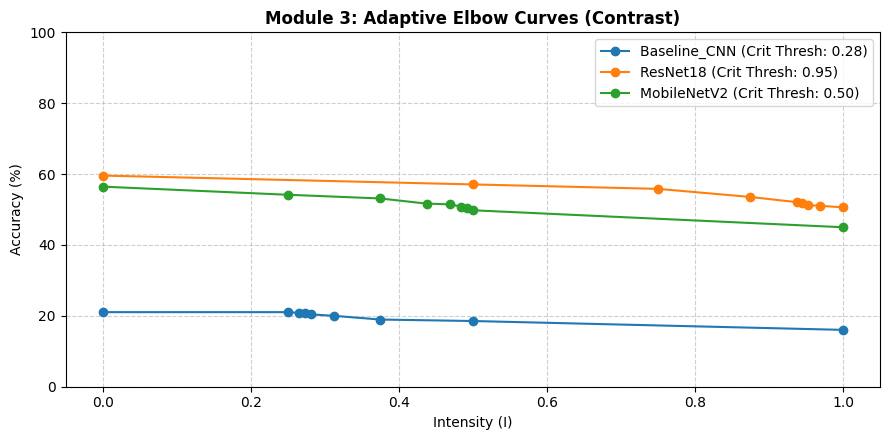


📊 MODULE 4: STATISTICAL METRICS AT CRITICAL THRESHOLDS (CONTRAST)
-----------------------------------------------------------------------------------------------
Model          | Thresh   | Accuracy   | MCC      | Macro F1   | Flip Rate   | ECE      | NLL     
-----------------------------------------------------------------------------------------------
Baseline_CNN   | 0.28     | 21.09      | 0.146    | 0.171      | 17.66       | 0.2381   | 2.3964  
ResNet18       | 0.95     | 50.78      | 0.458    | 0.493      | 36.56       | 0.0525   | 1.4154  
MobileNetV2    | 0.50     | 52.19      | 0.476    | 0.493      | 31.09       | 0.0455   | 1.3229  
-----------------------------------------------------------------------------------------------

🔍 MODULE 5: LIME QUALITATIVE FOCUS SHIFT (CONTRAST)
>>> Explaining [Baseline_CNN] failure at I=0.28 (Flipped to: airplane)


  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

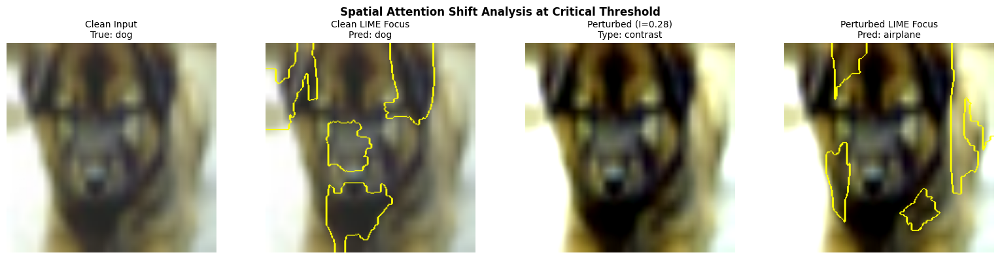

>>> Explaining [ResNet18] failure at I=0.95 (Flipped to: frog)


  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

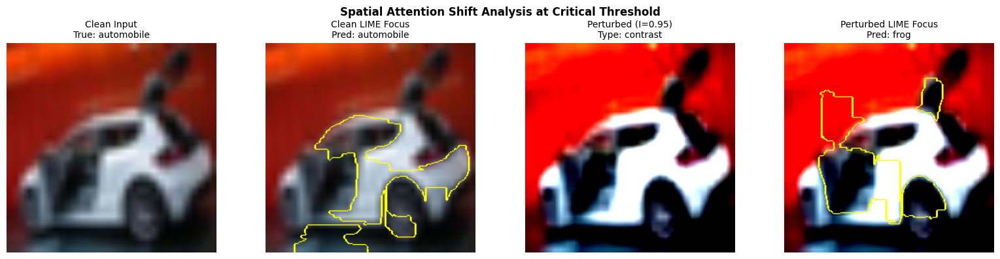

>>> Explaining [MobileNetV2] failure at I=0.50 (Flipped to: truck)


  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

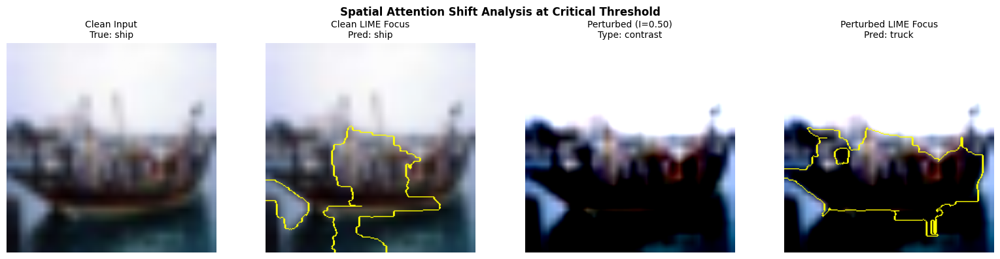



★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★
  EVALUATING PERTURBATION: [SENSOR_INTERFERENCE]
★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★


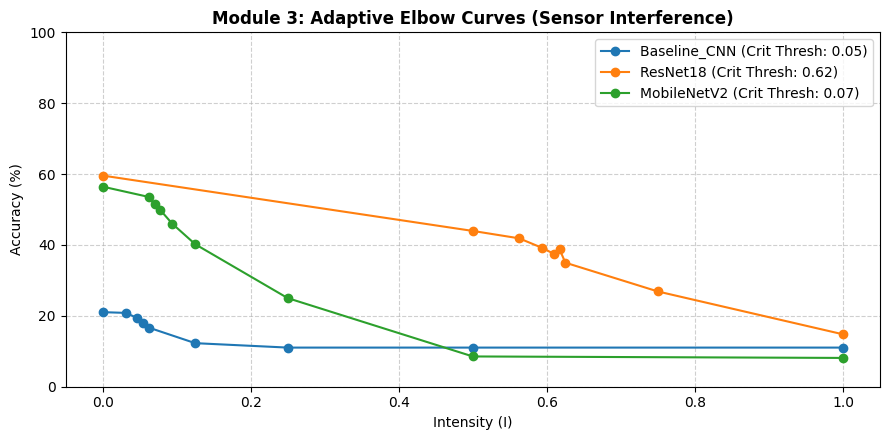


📊 MODULE 4: STATISTICAL METRICS AT CRITICAL THRESHOLDS (SENSOR_INTERFERENCE)
-----------------------------------------------------------------------------------------------
Model          | Thresh   | Accuracy   | MCC      | Macro F1   | Flip Rate   | ECE      | NLL     
-----------------------------------------------------------------------------------------------
Baseline_CNN   | 0.05     | 18.28      | 0.114    | 0.142      | 25.31       | 0.3135   | 2.6869  
ResNet18       | 0.62     | 35.62      | 0.325    | 0.367      | 49.69       | 0.1921   | 1.8289  
MobileNetV2    | 0.07     | 54.37      | 0.499    | 0.528      | 19.53       | 0.0578   | 1.2830  
-----------------------------------------------------------------------------------------------

🔍 MODULE 5: LIME QUALITATIVE FOCUS SHIFT (SENSOR_INTERFERENCE)
>>> Explaining [Baseline_CNN] failure at I=0.05 (Flipped to: airplane)


  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

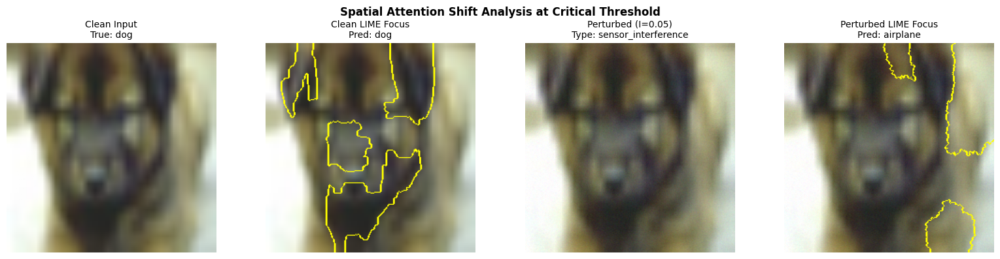

>>> Explaining [ResNet18] failure at I=0.62 (Flipped to: frog)


  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

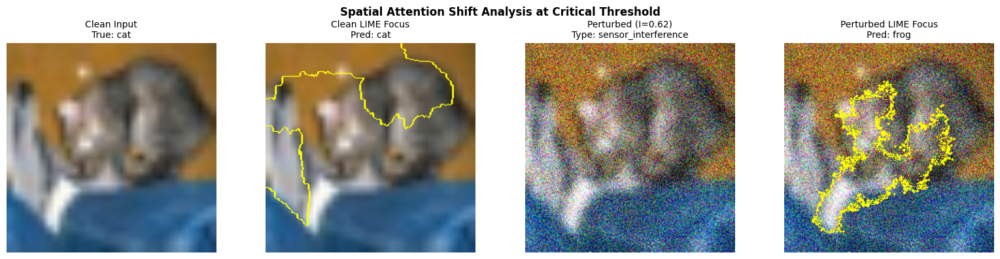

>>> Explaining [MobileNetV2] failure at I=0.07 (Flipped to: bird)


  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

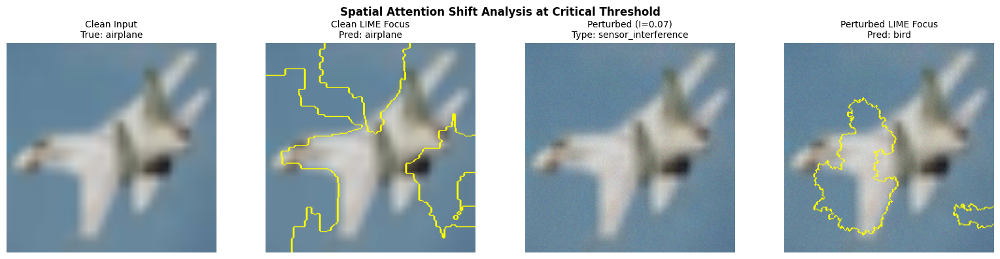



★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★
  EVALUATING PERTURBATION: [ENVIRONMENTAL_OBSTRUCTION]
★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★


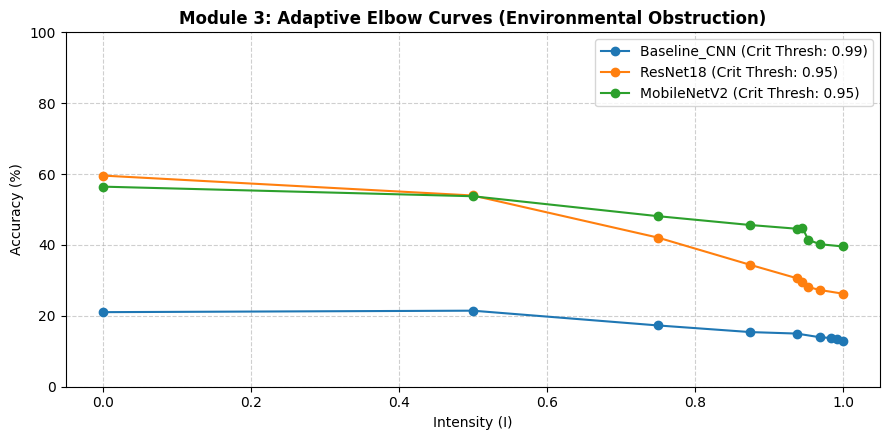


📊 MODULE 4: STATISTICAL METRICS AT CRITICAL THRESHOLDS (ENVIRONMENTAL_OBSTRUCTION)
-----------------------------------------------------------------------------------------------
Model          | Thresh   | Accuracy   | MCC      | Macro F1   | Flip Rate   | ECE      | NLL     
-----------------------------------------------------------------------------------------------
Baseline_CNN   | 0.99     | 12.66      | 0.036    | 0.064      | 46.09       | 0.2888   | 2.9142  
ResNet18       | 0.95     | 31.41      | 0.255    | 0.293      | 63.59       | 0.1573   | 2.0129  
MobileNetV2    | 0.95     | 44.22      | 0.388    | 0.437      | 48.44       | 0.0523   | 1.5328  
-----------------------------------------------------------------------------------------------

🔍 MODULE 5: LIME QUALITATIVE FOCUS SHIFT (ENVIRONMENTAL_OBSTRUCTION)
>>> Explaining [Baseline_CNN] failure at I=0.99 (Flipped to: airplane)


  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

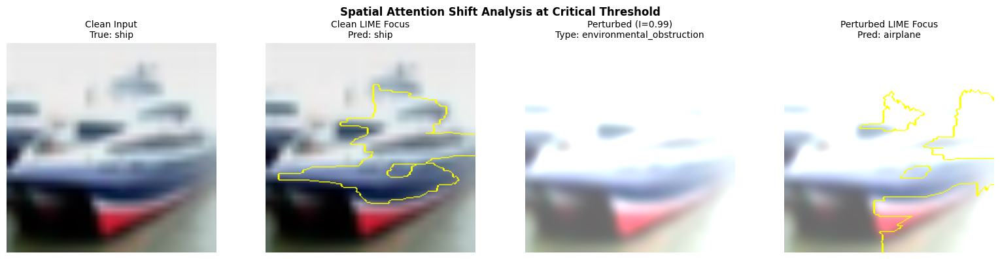

>>> Explaining [ResNet18] failure at I=0.95 (Flipped to: airplane)


  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

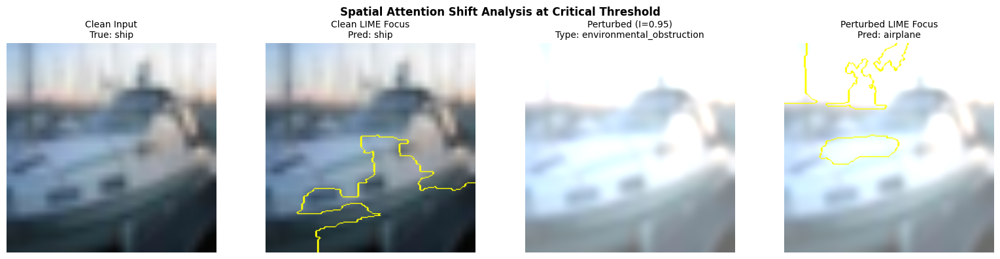

>>> Explaining [MobileNetV2] failure at I=0.95 (Flipped to: ship)


  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

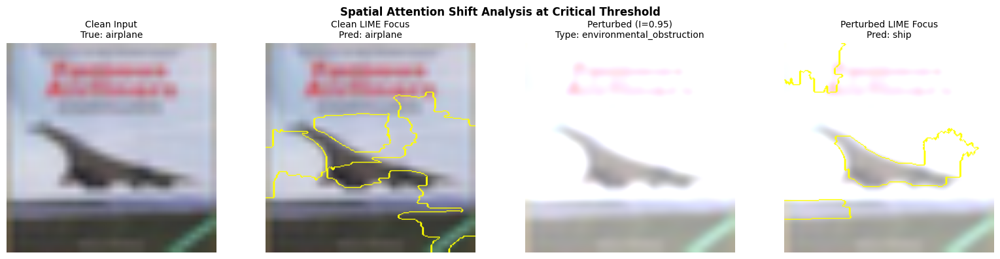



★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★
  EVALUATING PERTURBATION: [CAPTURE_INSTABILITY]
★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★


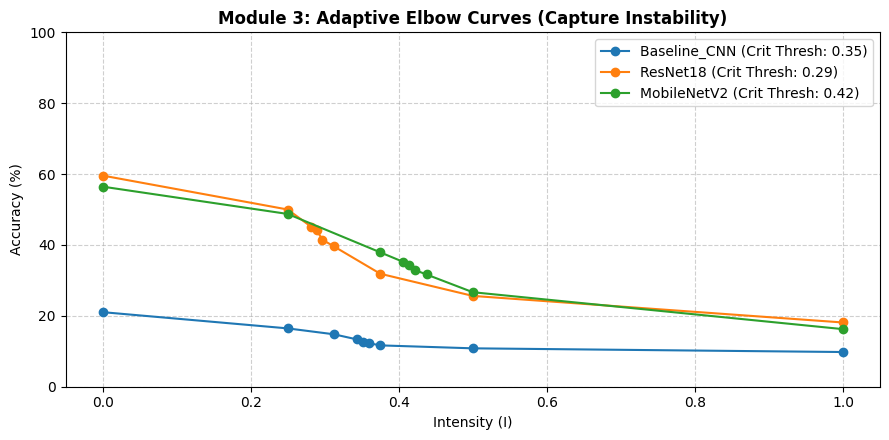


📊 MODULE 4: STATISTICAL METRICS AT CRITICAL THRESHOLDS (CAPTURE_INSTABILITY)
-----------------------------------------------------------------------------------------------
Model          | Thresh   | Accuracy   | MCC      | Macro F1   | Flip Rate   | ECE      | NLL     
-----------------------------------------------------------------------------------------------
Baseline_CNN   | 0.35     | 12.97      | 0.035    | 0.090      | 35.94       | 0.2873   | 2.7834  
ResNet18       | 0.29     | 42.19      | 0.366    | 0.413      | 45.47       | 0.0892   | 1.5721  
MobileNetV2    | 0.42     | 33.59      | 0.277    | 0.286      | 56.56       | 0.1863   | 2.1299  
-----------------------------------------------------------------------------------------------

🔍 MODULE 5: LIME QUALITATIVE FOCUS SHIFT (CAPTURE_INSTABILITY)
>>> Explaining [Baseline_CNN] failure at I=0.35 (Flipped to: frog)


  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

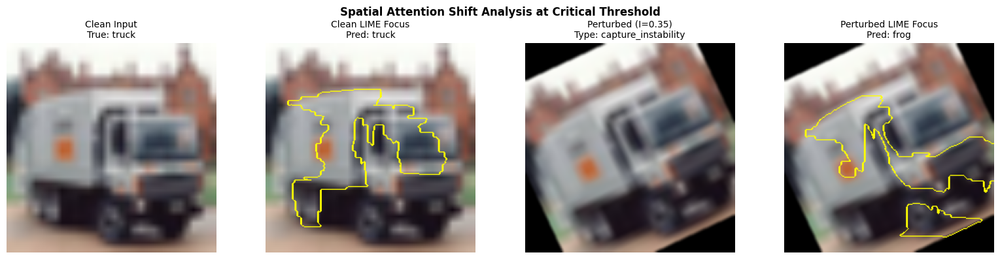

>>> Explaining [ResNet18] failure at I=0.29 (Flipped to: frog)


  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

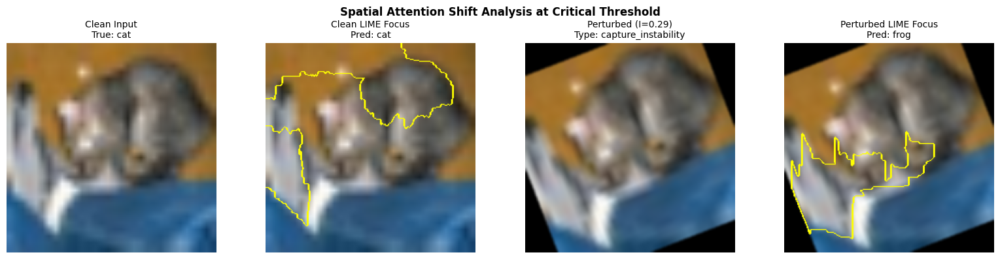

>>> Explaining [MobileNetV2] failure at I=0.42 (Flipped to: cat)


  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

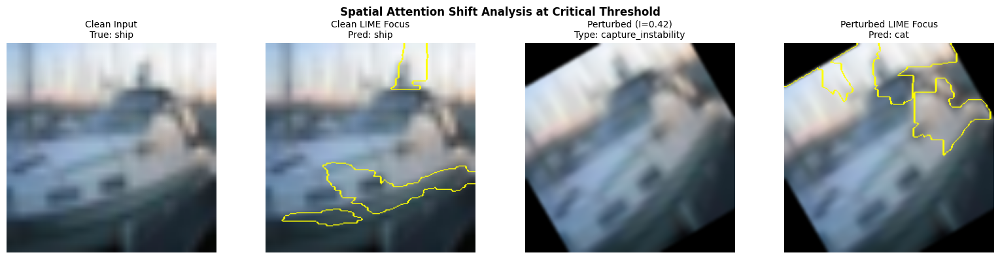

In [8]:
import os
import glob
import re
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# 1. Unnormalized Holdout Evaluation DataLoader
raw_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

raw_test_dataset = torchvision.datasets.CIFAR10(
    root=DATA_DIR, 
    train=False, 
    download=True, 
    transform=raw_test_transform
)

raw_test_loader = DataLoader(
    raw_test_dataset, batch_size=32, shuffle=False, num_workers=2, pin_memory=True
)

# 🔥 DYNAMIC LABEL EXTRACTION
classes = raw_test_dataset.classes 
print(f"Loaded Classes: {classes}")

# ==============================================================================
# 2. CHECKPOINT SCANNER
# ==============================================================================
trained_models = {}

print("\n" + "="*80)
print(f"📥 SCANNING FOR BEST CHECKPOINTS IN: {SAVE_DIR}/")
print("="*80)

for m_name in ["Baseline_CNN", "ResNet18", "MobileNetV2"]:
    search_pattern = f"{SAVE_DIR}/{m_name}_fold*_val*_train*.pt"
    available_files = glob.glob(search_pattern)
    
    if not available_files:
        print(f"⚠️ Warning: No checkpoints found for {m_name}")
        continue
        
    best_file, highest_val = None, -1.0
    
    for file_path in available_files:
        match = re.search(r'_val(\d+\.\d+)_', file_path)
        if match and float(match.group(1)) > highest_val:
            highest_val = float(match.group(1))
            best_file = file_path
                
    if best_file:
        print(f"[{m_name}] Loading top performer: {os.path.basename(best_file)}")
        ckpt = torch.load(best_file, map_location=device)
        m = build_model(m_name, num_classes=len(classes), in_channels=IN_CHANNELS)
        m.load_state_dict(ckpt['model_state_dict'])
        m = m.to(device)
        m.eval()
        trained_models[m_name] = m

# ==============================================================================
# 3. ENGINES & STRESS TEST EXECUTION
# ==============================================================================
pert_engine = PerturbationEngine(mean=DATASET_MEAN, std=DATASET_STD)
metric_engine = MetricEngine()

all_perturbations = [
    "gaussian_blur", "gaussian_noise", "brightness", "rotation", 
    "contrast", "sensor_interference", "environmental_obstruction", "capture_instability"
]

print("\n" + "="*95)
print("🚀 INITIATING MODULE 3 -> 4 -> 5 PIPELINE ACROSS ALL PERTURBATIONS")
print("="*95)

# Master Progress Bar
pbar_pert = tqdm(all_perturbations, desc="Master Evaluation Suite")

for p_type in pbar_pert:
    pbar_pert.set_postfix({"Current": p_type.upper()})
    
    tqdm.write("\n\n" + "★"*95)
    tqdm.write(f"  EVALUATING PERTURBATION: [{p_type.upper()}]")
    tqdm.write("★"*95)

    critical_thresholds = {}

    # --- A. Run Module 3: Adaptive Sampling ---
    plt.figure(figsize=(9, 4.5))
    for m_name, m_inst in trained_models.items():
        sampler = AdaptiveSamplingEngine(model=m_inst, dataloader=raw_test_loader, engine=pert_engine, device=device)
        intensities, accuracies, crit_thresh = sampler.run_adaptive_sampling(
            p_type=p_type, max_evals=9, max_batches=15
        )
        critical_thresholds[m_name] = crit_thresh
        plt.plot(intensities, accuracies, marker='o', label=f"{m_name} (Crit Thresh: {crit_thresh:.2f})")

    plt.title(f"Module 3: Adaptive Elbow Curves ({p_type.replace('_', ' ').title()})", fontweight='bold')
    plt.xlabel("Intensity (I)")
    plt.ylabel("Accuracy (%)")
    plt.ylim(0, 100)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # --- B. Run Module 4: Statistical Metrics ---
    tqdm.write(f"\n📊 MODULE 4: STATISTICAL METRICS AT CRITICAL THRESHOLDS ({p_type.upper()})")
    tqdm.write("-" * 95)
    tqdm.write(f"{'Model':<14} | {'Thresh':<8} | {'Accuracy':<10} | {'MCC':<8} | {'Macro F1':<10} | {'Flip Rate':<11} | {'ECE':<8} | {'NLL':<8}")
    tqdm.write("-" * 95)

    for m_name, m_inst in trained_models.items():
        thresh = critical_thresholds[m_name]
        metrics = metric_engine.evaluate_comprehensive_metrics(
            model=m_inst, dataloader=raw_test_loader, engine=pert_engine,
            p_type=p_type, intensity=thresh, device=device, max_batches=20
        )
        tqdm.write(f"{m_name:<14} | {thresh:<8.2f} | {metrics['Accuracy (%)']:<10.2f} | {metrics['MCC']:<8.3f} | {metrics['Macro F1']:<10.3f} | {metrics['Flip Rate (%)']:<11.2f} | {metrics['ECE']:<8.4f} | {metrics['NLL']:<8.4f}")
    tqdm.write("-" * 95)

    # --- C. Run Module 5: Dynamic LIME Hunter ---
    tqdm.write(f"\n🔍 MODULE 5: LIME QUALITATIVE FOCUS SHIFT ({p_type.upper()})")
    
    def find_flip_case(m_inst, p_type, thresh, max_search=100):
        m_inst.eval()
        for idx in range(min(max_search, len(raw_test_dataset))):
            raw_img, true_lbl = raw_test_dataset[idx]
            with torch.no_grad():
                clean_tensor = pert_engine.normalize(raw_img.unsqueeze(0)).to(device)
                if m_inst(clean_tensor).argmax(dim=1).item() != true_lbl: 
                    continue 
                
                pert_tensor = pert_engine.apply_perturbation(raw_img.unsqueeze(0), p_type, thresh).to(device)
                pert_pred = m_inst(pert_tensor).argmax(dim=1).item()
                
                if pert_pred != true_lbl:
                    return raw_img, true_lbl, pert_pred
        return raw_test_dataset[0][0], raw_test_dataset[0][1], -1

    for m_name, m_inst in trained_models.items():
        crit_thresh = critical_thresholds[m_name]
        fail_img, true_lbl, wrong_pred = find_flip_case(m_inst, p_type, crit_thresh)
        
        if wrong_pred != -1:
            tqdm.write(f">>> Explaining [{m_name}] failure at I={crit_thresh:.2f} (Flipped to: {classes[wrong_pred]})")
        else:
            tqdm.write(f">>> Explaining [{m_name}] at I={crit_thresh:.2f} (Fallback image used)")
            
        lime_engine = LIMEExplainabilityEngine(model=m_inst, engine=pert_engine, classes=classes, device=device)
        lime_engine.explain_critical_sample(
            raw_img_tensor=fail_img, label_idx=true_lbl, p_type=p_type, 
            critical_intensity=crit_thresh, num_samples=150
        )


🖼️ RENDERING COMPARATIVE PERTURBATION SAMPLES (True Class: DOG)

>>> Generating Matrix for Architecture: [Baseline_CNN]


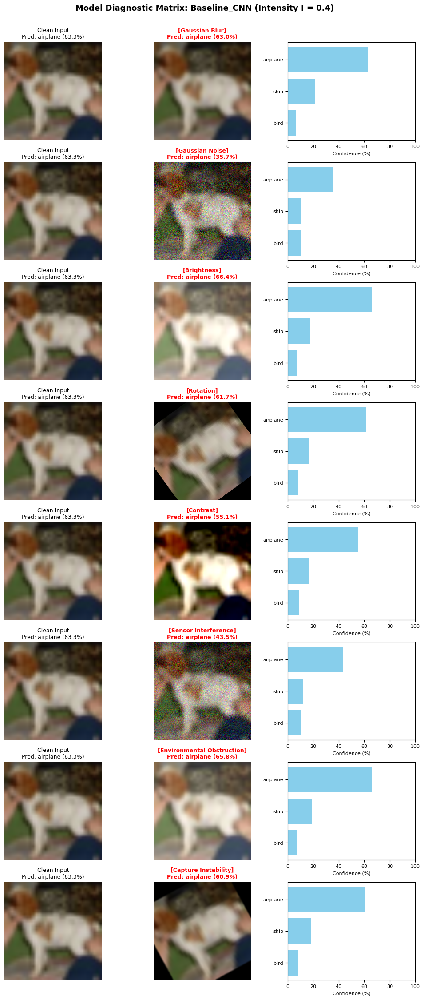


>>> Generating Matrix for Architecture: [ResNet18]


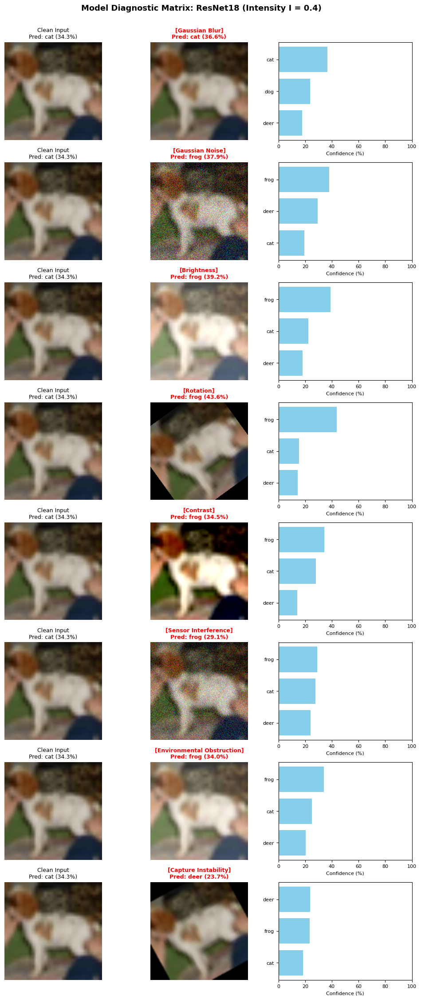


>>> Generating Matrix for Architecture: [MobileNetV2]


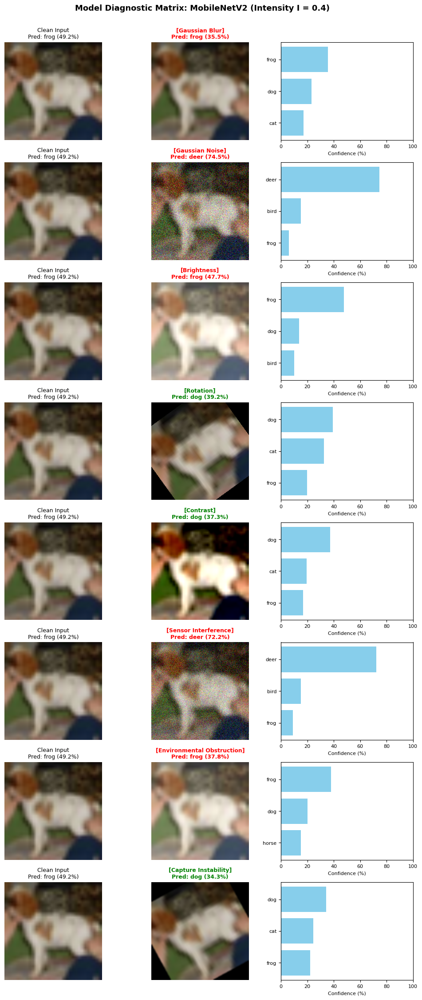

In [9]:
# 1. Select a clean sample from raw test dataset
sample_idx = 12  
raw_sample_img, true_label = raw_test_dataset[sample_idx]

# Classes are dynamically inherited from Snippet 8
all_perturbations = [
    "gaussian_blur", "gaussian_noise", "brightness", "rotation", 
    "contrast", "sensor_interference", "environmental_obstruction", "capture_instability"
]

eval_intensity = 0.40  # Meaningful stress-test intensity

print("\n" + "="*90)
print(f"🖼️ RENDERING COMPARATIVE PERTURBATION SAMPLES (True Class: {classes[true_label].upper()})")
print("="*90)

for m_name, model in trained_models.items():
    print(f"\n>>> Generating Matrix for Architecture: [{m_name}]")
    model.eval()
    
    fig, axes = plt.subplots(len(all_perturbations), 3, figsize=(10, 2.8 * len(all_perturbations)))
    
    with torch.no_grad():
        clean_tensor = pert_engine.normalize(raw_sample_img.unsqueeze(0)).to(device)
        clean_probs = F.softmax(model(clean_tensor), dim=1).cpu().numpy()[0]
        clean_pred = np.argmax(clean_probs)
        clean_conf = clean_probs[clean_pred] * 100.0

    for idx, p_type in enumerate(all_perturbations):
        with torch.no_grad():
            raw_pert = pert_engine.apply_raw_perturbation(raw_sample_img.unsqueeze(0), p_type, eval_intensity).squeeze(0)
            norm_pert = pert_engine.normalize(raw_pert.unsqueeze(0)).to(device)
            pert_probs = F.softmax(model(norm_pert), dim=1).cpu().numpy()[0]
            pert_pred = np.argmax(pert_probs)
            pert_conf = pert_probs[pert_pred] * 100.0
            
        clean_display = raw_sample_img.permute(1, 2, 0).numpy()
        pert_display = raw_pert.permute(1, 2, 0).numpy()

        axes[idx, 0].imshow(clean_display)
        axes[idx, 0].set_title(f"Clean Input\nPred: {classes[clean_pred]} ({clean_conf:.1f}%)", fontsize=9)
        axes[idx, 0].axis('off')

        axes[idx, 1].imshow(pert_display)
        is_correct = (pert_pred == true_label)
        status_color = "green" if is_correct else "red"
        axes[idx, 1].set_title(f"[{p_type.replace('_', ' ').title()}]\nPred: {classes[pert_pred]} ({pert_conf:.1f}%)", 
                               fontsize=9, color=status_color, fontweight='bold')
        axes[idx, 1].axis('off')

        top3_indices = np.argsort(pert_probs)[-3:][::-1]
        top3_labels = [classes[i] for i in top3_indices]
        top3_vals = [pert_probs[i] * 100.0 for i in top3_indices]
        
        axes[idx, 2].barh(top3_labels, top3_vals, color='skyblue')
        axes[idx, 2].set_xlim(0, 100)
        axes[idx, 2].set_xlabel("Confidence (%)", fontsize=8)
        axes[idx, 2].invert_yaxis()
        axes[idx, 2].tick_params(axis='both', which='major', labelsize=8)

    plt.suptitle(f"Model Diagnostic Matrix: {m_name} (Intensity I = {eval_intensity})", fontsize=13, fontweight='bold', y=1.002)
    plt.tight_layout()
    plt.show()